### Question 1.
You're a data analyst at UrbanCart, an e-commerce platform. The marketing head proudly announces: "Our average order value (AOV) this month is ₹4,200 — up from ₹2,800 last month! Great campaign
performance." 
You pull the raw order data for this month (in ₹): 800, 950, 1100, 1200, 1350,
1400, 1500, 42,000, 38,500

### Task: 
Evaluate the marketing head's claim. What's actually happening here, and what number should you present in the review meeting instead?

Total Revenue = 88800
Average Order Value = 9866.67
Median Order Value = 1350.0


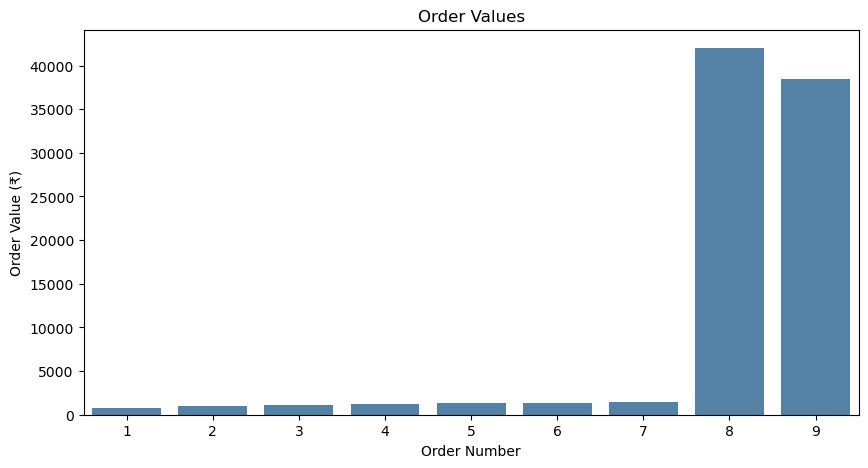

In [8]:
import pandas as pd # Data Manipulation and Analysis
import numpy as np # Mathematical calculations
import matplotlib.pyplot as plt
import seaborn as sns # matplotlib & seaborn = charts and visualizations
# Display plots inside notebook
%matplotlib inline

# Creating a DataFrame from the raw order values provided in the case study.
orders = [800, 950, 1100, 1200, 1350, 1400, 1500, 42000, 38500]
df = pd.DataFrame({
    'Order_Value': orders
})
df
# Sum of all order values.
total_revenue = df['Order_Value'].sum()
print("Total Revenue =", total_revenue)

# Mean AOV is calculated by dividing total revenue by total number of orders.
mean_aov = df['Order_Value'].mean()
print("Average Order Value =", round(mean_aov,2))

# Median represents the middle order value and is less affected by extreme outliers.
median_aov = df['Order_Value'].median()
print("Median Order Value =", median_aov)

#Creating Summary Table
summary = pd.DataFrame({
    'Metric':['Mean AOV','Median Order Value'],
    'Value':[mean_aov,median_aov]
})
summary

# This chart shows that most orders fall between ₹800 and ₹1,500.
# Two orders (₹38,500 and ₹42,000) are significantly higher than the rest.
plt.figure(figsize=(10,5))
sns.barplot(
    x=df.index + 1,
    y=df['Order_Value'],
    color='steelblue'
)
plt.title('Order Values'), plt.xlabel('Order Number'), plt.ylabel('Order Value (₹)')
plt.show()


plt.figure(figsize=(8,4))
sns.boxplot(
    x=df['Order_Value']
)
plt.title('Box Plot of Order Values')
plt.xlabel('Order Value (₹)')
plt.show()

"""Interpretation
The box plot clearly identifies ₹38,500 and ₹42,000 as extreme observations.
These values are significantly higher than the majority of transactions and inflate the average order value.
Therefore, the Mean AOV may not accurately represent the spending pattern of a typical customer."""

# Displaying the distribution of data.
plt.figure(figsize=(8,5))
sns.histplot(
    df['Order_Value'],
    bins=5,
    kde=True
)
plt.title('Distribution of Order Values')
plt.xlabel('Order Value (₹)')
plt.ylabel('Frequency')
plt.show()



comparison = pd.DataFrame({
    'Metric':['Mean AOV','Median'],
    'Value':[mean_aov, median_aov]
})
plt.figure(figsize=(7,5))
sns.barplot(
    x='Metric',
    y='Value',
    data=comparison,
    palette='Set2'
)
plt.title('Mean vs Median Comparison')
plt.ylabel('Value (₹)')
plt.show()

# Findings
1. Mean AOV = ₹9,866.67
2. Median Order Value = ₹1,350
3. Most order values lie between ₹800 and ₹1,500.
4. Two orders (₹38,500 and ₹42,000) significantly increase the Mean AOV.
5. The distribution is highly right-skewed.

# Business Interpretation
The increase in Average Order Value is primarily driven by two unusually large transactions rather than a widespread increase in customer spending.
Therefore, the marketing campaign cannot be considered successful solely on the basis of Average Order Value.

# Recommendation
1. Present Median Order Value (₹1,350) alongside Mean AOV.
2. Investigate high-value transactions separately.
3. Segment customers into Regular and High-Value customers.
4. Measure campaign success using additional KPIs such as:
   - Conversion Rate
   - Total Orders
   - Customer Acquisition Cost
   - Revenue by Customer Segment

# Final Recommendation to Management
The Median Order Value (₹1,350) provides a more reliable representation of a typical UrbanCart customer than the Mean AOV (₹9,866.67). The observed increase in AOV appears driven by a small number of high-value orders rather than broad changes in customer behavior.

### Question 2. 
The HR head at a 200-person startup wants to benchmark salaries against the market. 
She says: "Just tell me the average salary in our Sales team."
Sales team salaries (₹ lakhs/year): 6, 6, 6, 6, 7, 7, 8, 9, 45 (the last is the VP of
Sales)

### Task: 
Which measure of central tendency should be reported to HR for benchmarking purposes, and why? What would you tell her about using this number externally?

Mean Salary: 11.11 LPA
Median Salary: 7.00 LPA
Mode Salary: 6.00 LPA


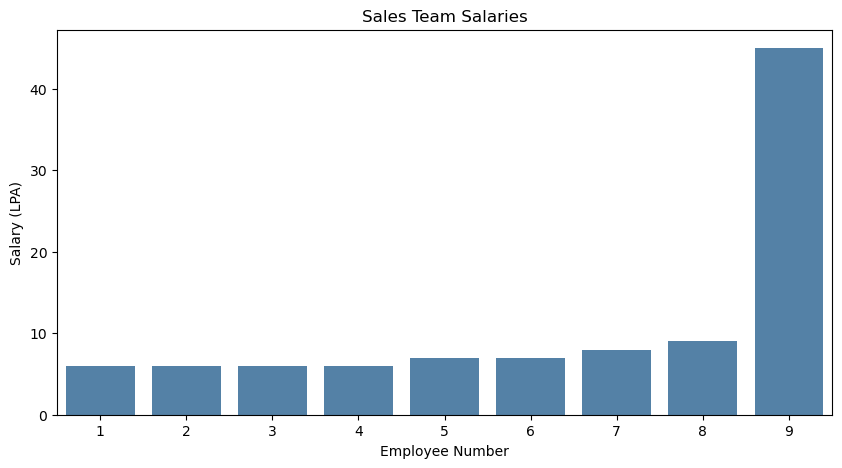

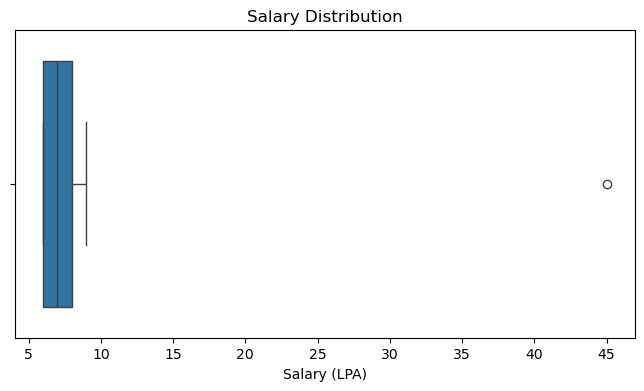

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Creating data frame as per the values in Question. 
salaries = [6,6,6,6,7,7,8,9,45]
df = pd.DataFrame({
    'Salary_LPA': salaries
})
df

# Summary Table
mean_salary = df['Salary_LPA'].mean()
median_salary = df['Salary_LPA'].median()
mode_salary = df['Salary_LPA'].mode()[0]

print(f"Mean Salary: {mean_salary:.2f} LPA")
print(f"Median Salary: {median_salary:.2f} LPA")
print(f"Mode Salary: {mode_salary:.2f} LPA")

# Bar Chart
plt.figure(figsize=(10,5))
sns.barplot(
    x=df.index + 1,
    y='Salary_LPA',
    data=df,
    color='steelblue'
)
plt.title('Sales Team Salaries')
plt.xlabel('Employee Number')
plt.ylabel('Salary (LPA)')
plt.show()

#Box Plot
plt.figure(figsize=(8,4))
sns.boxplot(
    x=df['Salary_LPA']
)
plt.title('Salary Distribution')
plt.xlabel('Salary (LPA)')
plt.show()

## Conclusion
The box plot clearly identifies ₹45 LPA as an extreme outlier. This outlier significantly inflates the mean salary, making the median a more reliable measure for salary benchmarking purposes.

## Question 3. 
Which Delivery Partner Is More Reliable?
QuickShip Logistics is choosing between two delivery partners based on
delivery time consistency (in hours) for the same route, sampled over 10
deliveries:
● Partner A: 24, 25, 23, 26, 24, 25, 23, 24, 26, 25 (Mean = 24.5)
● Partner B: 18, 30, 15, 33, 20, 28, 16, 32, 19, 34 (Mean = 24.5)
Both have the same mean delivery time. The ops manager says "they're
equally good, pick the cheaper one."

## Task:
Is the ops manager right? Compute a measure that tells the real story, and give your recommendation.

Partner A Mean: 24.5
Partner B Mean: 24.5
Partner A Std Dev: 1.08
Partner B Std Dev: 7.58


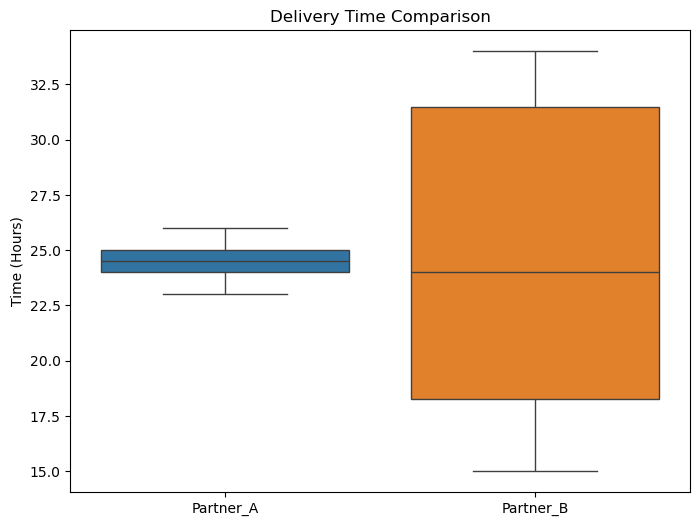

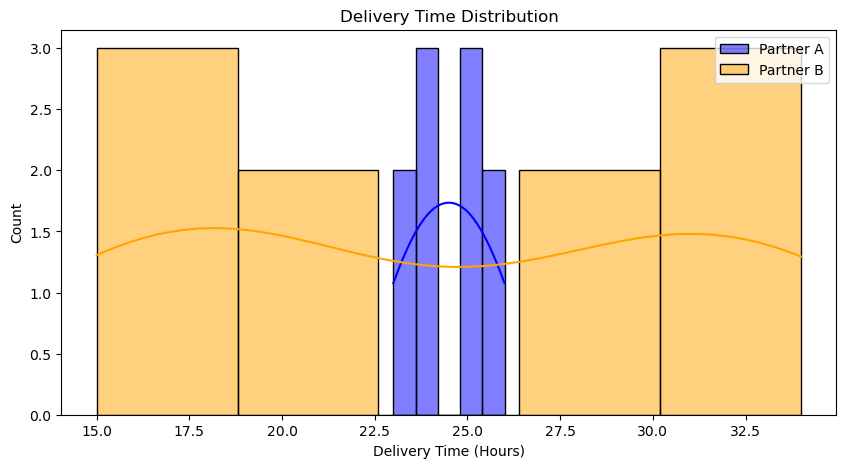

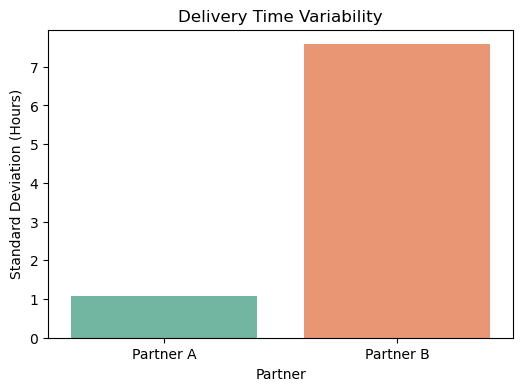

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data frame for the shared values in Question. 
# Creating datasets for delivery times of both logistics partners.
partner_a = [24,25,23,26,24,25,23,24,26,25]
partner_b = [18,30,15,33,20,28,16,32,19,34]
df = pd.DataFrame({
    'Partner_A': partner_a,
    'Partner_B': partner_b
})
df

#Calculating Mean for both the partner's 
mean_a = np.mean(partner_a)
mean_b = np.mean(partner_b)
print("Partner A Mean:", mean_a)
print("Partner B Mean:", mean_b)

# Standard deviation measures the variability of delivery times. Lower values indicate greater consistency.
std_a = np.std(partner_a, ddof=1)
std_b = np.std(partner_b, ddof=1)
print("Partner A Std Dev:", round(std_a,2))
print("Partner B Std Dev:", round(std_b,2))

#Creating summary table
summary = pd.DataFrame({
    'Metric':['Mean','Standard Deviation'],
    'Partner A':[mean_a,std_a],
    'Partner B':[mean_b,std_b]
})
summary

plt.figure(figsize=(8,6))
sns.boxplot(data=df)
plt.title('Delivery Time Comparison')
plt.ylabel('Time (Hours)')
plt.show()
"""The box plot shows that Partner A has a much smaller spread of delivery times than Partner B.
This indicates better delivery consistency."""

# Distribution chart
plt.figure(figsize=(10,5))
sns.histplot(partner_a, color='blue', label='Partner A', kde=True)
sns.histplot(partner_b, color='orange', label='Partner B', kde=True)
plt.legend()
plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Time (Hours)')
plt.show()

# Bar Chart of Standard Deviation. 
std_df = pd.DataFrame({
    'Partner':['Partner A','Partner B'],
    'Standard Deviation':[std_a,std_b]
})
plt.figure(figsize=(6,4))
sns.barplot(
    x='Partner',
    y='Standard Deviation',
    hue="Partner",
    data=std_df,
    palette='Set2',
    legend=False,
)
plt.title('Delivery Time Variability')
plt.ylabel('Standard Deviation (Hours)')
plt.show()

## Conclusion: Partner B's standard deviation is approximately 6.6 times higher than Partner A's (7.15 vs 1.08 hours), indicating substantially lower reliability and predictability despite having the same average delivery time.

## Question 4. 
A SaaS company's support team resolves tickets in the following times
(hours): 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 45
The support lead wants to identify which resolution times are "abnormal" so she can investigate root causes, without just eyeballing the data. 

## Task: 
Use a statistical method to objectively flag outliers. What would you investigate about the flagged case(s)?

Q1 = 3.5
Q3 = 6.0
IQR = 2.5
Lower Bound = -0.25
Upper Bound = 9.75


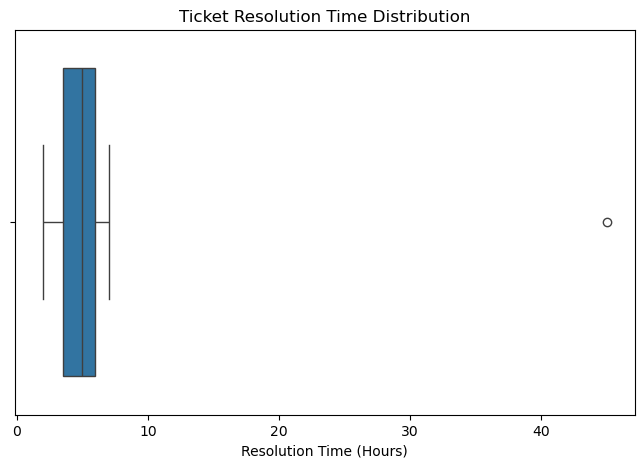

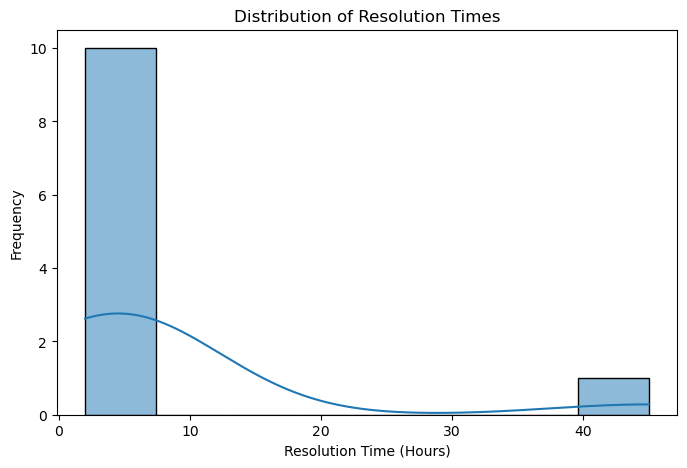

,Resolution_Time,Outlier
0,2,No
1,3,No
2,3,No
3,4,No
4,4,No
5,5,No
6,5,No
7,6,No
8,6,No
9,7,No


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Creating Dataset with the shared resolution time. 
resolution_times = [2,3,3,4,4,5,5,6,6,7,45]
df = pd.DataFrame({
    'Resolution_Time': resolution_times
})
df

#Calculating Quartile
Q1 = df['Resolution_Time'].quantile(0.25)
Q3 = df['Resolution_Time'].quantile(0.75)
print("Q1 =", Q1)
print("Q3 =", Q3)

#Calculating IQR
IQR = Q3 - Q1
print("IQR =", IQR)

#Calculating the outliers limit
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower Bound =", lower_bound)
print("Upper Bound =", upper_bound)

#Identifying Outliers
outliers = df[
    (df['Resolution_Time'] < lower_bound) |
    (df['Resolution_Time'] > upper_bound)
]
outliers

#Box Plot
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df['Resolution_Time']
)
plt.title('Ticket Resolution Time Distribution')
plt.xlabel('Resolution Time (Hours)')
plt.show()
# The box plot clearly shows 45 hours as an extreme outlier.
# All other ticket resolution times are clustered between 2 and 7 hours.

# Histogram
plt.figure(figsize=(8,5))
sns.histplot(
    df['Resolution_Time'],
    bins=8,
    kde=True
)
plt.title('Distribution of Resolution Times')
plt.xlabel('Resolution Time (Hours)')
plt.ylabel('Frequency')
plt.show()

# Highlighting the oUtlier values.
df['Outlier'] = np.where(
    (df['Resolution_Time'] < lower_bound) |
    (df['Resolution_Time'] > upper_bound),
    'Yes',
    'No'
)
df

## Question 5. 
Two ad channels both average 500 daily website visits over the last 14 days. Finance wants to know which channel to scale budget on, purely based on how "stable and forecastable" the traffic is.
Channel X daily visits have a standard deviation of 40. Channel Y has a
standard deviation of 180.

## Task: 
Beyond just picking the lower-SD channel, explain what additional business context you'd want before recommending a budget shift.

C:\Users\vijaykumar\AppData\Local\Temp\ipykernel_27048\3124504426.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


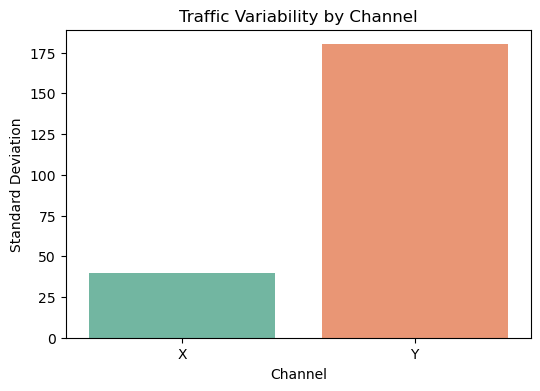

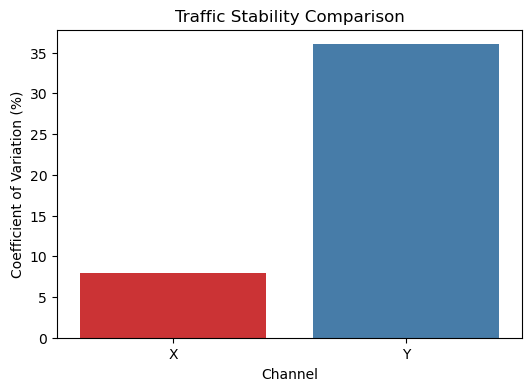

In [42]:
#Visualizing the data of standard deviation
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
mean_visits = [500, 500]
std_dev = [40, 180]
df = pd.DataFrame({
    'Channel':['X','Y'],
    'Mean_Visits':mean_visits,
    'Standard_Deviation':std_dev
})
df

# Calculating the Co-efficient of variation
df['CV (%)'] = (df['Standard_Deviation'] / df['Mean_Visits']) * 100
df

plt.figure(figsize=(6,4))

sns.barplot(
    x='Channel',
    y='Standard_Deviation',
    data=df,
    palette='Set2'
)
plt.title('Traffic Variability by Channel')
plt.ylabel('Standard Deviation')
plt.show()

#Visualizing the Co-efficient of variation
plt.figure(figsize=(6,4))

sns.barplot(
    x='Channel',
    y='CV (%)',
    hue='Channel',
    data=df,
    palette='Set1',
    legend=False,
)
plt.title('Traffic Stability Comparison')
plt.ylabel('Coefficient of Variation (%)')
plt.show()

## Question 6. 
Ice Cream, Drowning, and a Dangerous Report A junior analyst on your team submits a report: "We found a strong positive correlation (r = 0.87) between the number of push notifications sent and app
uninstalls. We should immediately reduce notifications to near zero to fix
retention." 

## Task: 
As the senior analyst reviewing this before it goes to leadership, what do you say, and what would you actually do before recommending an action?

Correlation: 0.99


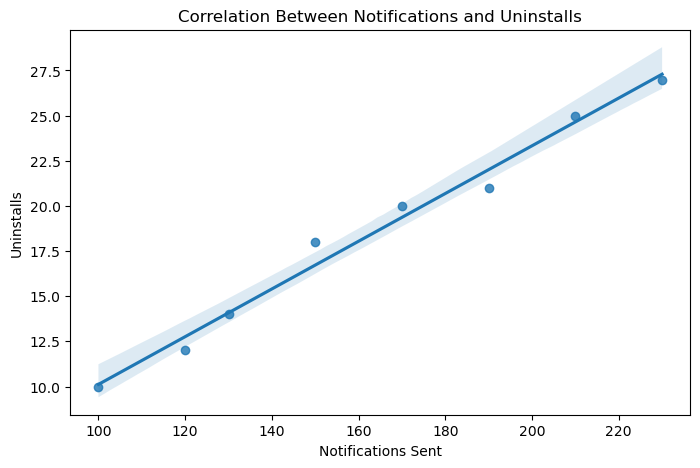

In [45]:
import pandas as pd
#Creating sample data
data = {
    'Notifications_Sent':[100,120,130,150,170,190,210,230],
    'Uninstalls':[10,12,14,18,20,21,25,27]
}
df = pd.DataFrame(data)
df

#Calculating Correlation
correlation = df['Notifications_Sent'].corr(df['Uninstalls'])
print(f"Correlation: {correlation:.2f}")
# Correlation measures the strength and direction
# of a linear relationship between two variables.

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.regplot(
    x='Notifications_Sent',
    y='Uninstalls',
    data=df
)
plt.title('Correlation Between Notifications and Uninstalls')
plt.xlabel('Notifications Sent')
plt.ylabel('Uninstalls')
plt.show()

## Conclusion
Although the scatter plot shows a strong positive correlation, correlation alone does not establish that notifications are causing users to uninstall the application. Further investigation and controlled experimentation are required before making product decisions.

## Question 7. 
The CEO of a food delivery app walks into your team's meeting and says:
"Growth has stalled. Fix it."

## Task:
This is not an analytical question yet. Write down 4-5 specific, answerable analytical questions you would break this down into, and briefly note what data you'd need for each.

Before taking action, the company should conduct a structured analysis across the five areas:
Acquisition → Retention → Order Frequency → Operations → Segmentation

1. Customer Acquisition
Question: Are we getting fewer new customers?
New user signups
First-time orders
Marketing campaign performance
Customer acquisition cost (CAC)
Possible Finding: If new user signups are declining, growth may be slowing because fewer customers are entering the platform.

2. Customer Retention
Question: Are existing customers returning?
Repeat purchases
Customer retention rate
Churn rate
Customer cohorts
Possible Finding: If customers place one order and never return, retention is the primary growth issue.

3. Order Frequency
Question: Are customers ordering less often?
Orders per customer
Monthly active users
Average order frequency
Possible Finding: Customers may still be active but ordering less frequently, reducing overall growth.

4. Operational Performance
Question: Is customer experience driving customers away?
Delivery times
Order cancellations
Refund rates
Customer ratings and complaints
Possible Finding: Poor delivery experiences or service issues can directly reduce customer retention and repeat orders.

5. Segment Analysis
Question: Where exactly is growth slowing?
Performance by city
Customer segments
Restaurant partners
Revenue by region
Possible Finding: Overall growth may appear flat, while certain cities or customer segments are underperforming.

This approach will help identify the true root cause of stalled growth and ensure that management invests in the right solution rather than treating symptoms.

Growth has not "stalled" by itself; rather, one or more parts of the business funnel are underperforming. By analyzing customer acquisition, retention, order frequency, operational performance, and segment-level trends, leadership can pinpoint the exact cause and implement targeted, data-driven actions to restart growth.

## Question 8. The Leaky Funnel
An online furniture store has this funnel for the last 30 days:
Stage Users
Product Page
View
100,000
Add to Cart 18,000
Checkout Started 12,000
Payment Page
Reached
10,500
Order Completed 4,200

## Task: 
Identify the biggest drop-off stage (by conversion rate, not absolute number) and propose two plausible business hypotheses for it, plus how you'd test each.

## Funnel Analysis
Stage	Users	Conversion Rate	Drop-off
Product View → Add to Cart	100,000 → 18,000	18%	82%
Add to Cart → Checkout Started	18,000 → 12,000	66.7%	33.3%
Checkout Started → Payment Page	12,000 → 10,500	87.5%	12.5%
Payment Page → Order Completed	10,500 → 4,200	40%	60%

Biggest Drop-off Stage
Product Page View → Add to Cart
Conversion Rate = 18%
Drop-off Rate = 82%
This is the largest leak in the funnel.

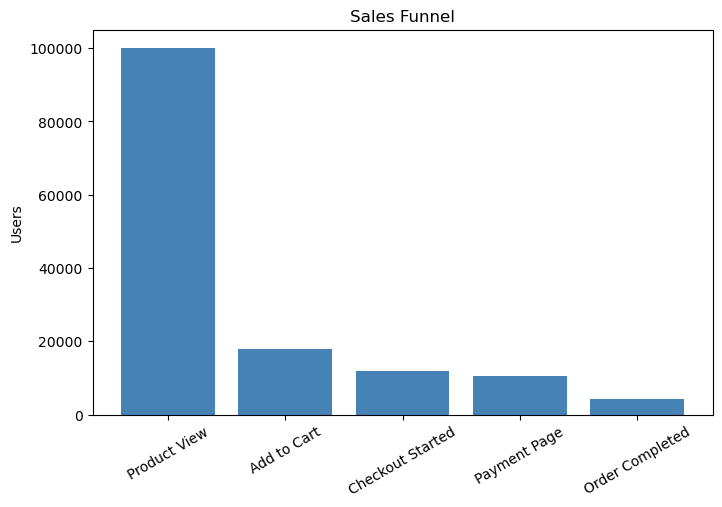

In [48]:
import pandas as pd
funnel = pd.DataFrame({
    'Stage': [
        'Product View',
        'Add to Cart',
        'Checkout Started',
        'Payment Page',
        'Order Completed'
    ],
    'Users': [100000, 18000, 12000, 10500, 4200]
})
funnel

# Calculating the conversion rate
funnel['Conversion_Rate_%'] = funnel['Users'].pct_change()
funnel['Conversion_Rate_%'] = (
    funnel['Users'] /
    funnel['Users'].shift(1)
) * 100
funnel

#Cretaing the visualization:

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(
    funnel['Stage'],
    funnel['Users'],
    color='steelblue'
)
plt.title('Sales Funnel')
plt.ylabel('Users')
plt.xticks(rotation=30)
plt.show()

## Question 9: A subscription streaming service missed its monthly revenue target by
12%. Revenue = Active Subscribers × Average Revenue Per User (ARPU).
Task: Build out a simple KPI tree (2 levels deep) to decompose "Revenue" and
identify where you'd look first, given this additional fact: Active Subscribers
grew 3% MoM, but ARPU fell 14% MoM.

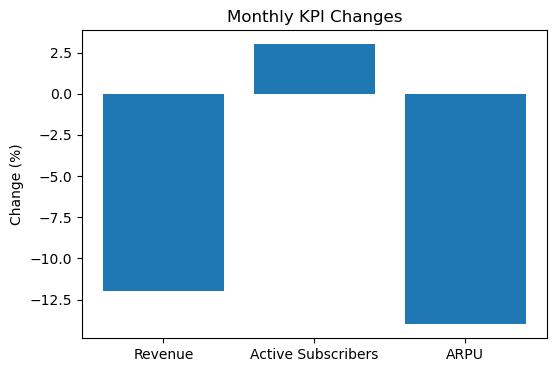

In [7]:
import pandas as pd
kpi_data = {
    'Metric': ['Revenue', 'Active Subscribers', 'ARPU'],
    'Change (%)': [-12, 3, -14]
}
df = pd.DataFrame(kpi_data)
df

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(df['Metric'], df['Change (%)'])

plt.title('Monthly KPI Changes')
plt.ylabel('Change (%)')

plt.show()

### Key Finding
- Revenue decreased by 12%.
- Active Subscribers increased by 3%.
- ARPU decreased by 14%.

Although the subscriber base is growing, the business is earning less revenue per subscriber. Therefore, ARPU is the primary KPI that requires further investigation.

### Areas to Investigate
1. Pricing changes
2. Discounts and promotions
3. Subscription plan mix
4. Premium customer churn

## Question 10. 
A fashion e-commerce brand currently segments its email marketing by age and gender only, and open rates have been flat for 6 months.

## Task: 
Propose an alternative segmentation framework using at least 3 dimensions that would likely drive more relevant targeting, and explain the business action tied to each segment.

In [12]:
import pandas as pd
df = pd.DataFrame({
    'Customer':['C1','C2','C3','C4','C5'],
    'Orders':[12,5,1,8,2],
    'Spend':[50000,20000,5000,30000,8000],
    'Category':['Women','Footwear','Women','Men','Accessories']
})
df

# Creating frequency segment
def frequency_segment(x):
    if x >= 10:
        return "Frequent"
    elif x >= 3:
        return "Occasional"
    else:
        return "One-Time"

df['Frequency_Segment'] = df['Orders'].apply(frequency_segment)

# Creating value Segment 
def value_segment(x):
    if x >= 30000:
        return "High Value"
    elif x >= 10000:
        return "Medium Value"
    else:
        return "Low Value"
df['Value_Segment'] = df['Spend'].apply(value_segment)

# Creating Final Segments
def value_segment(x):
    if x >= 30000:
        return "High Value"
    elif x >= 10000:
        return "Medium Value"
    else:
        return "Low Value"
df['Value_Segment'] = df['Spend'].apply(value_segment)

# Display all three segmentation dimensions

final_segments = df[[
    'Customer',
    'Frequency_Segment',
    'Value_Segment',
    'Category'
]]
print(final_segments)

  Customer Frequency_Segment Value_Segment     Category
0       C1          Frequent    High Value        Women
1       C2        Occasional  Medium Value     Footwear
2       C3          One-Time     Low Value        Women
3       C4        Occasional    High Value          Men
4       C5          One-Time     Low Value  Accessories


## Question 11. 
A D2C skincare brand has 5,000 customers. You calculate RFM scores (1=worst, 5=best) for each. Here are 3 representative customers:
Customer
Recency (days
since last order)
Frequency
(orders in 1 yr)
Monetary
(total spend)
R
Score
F
Score
M
Score
A 5 12 ₹45,000 5 5 5
B 210 8 ₹38,000 1 4 4
C 15 1 ₹1,200 5 1 1
Task: Label each customer's RFM segment in plain business terms, and give a
specific, different marketing action for each.

In [13]:
import pandas as pd

df = pd.DataFrame({
    'Customer':['A','B','C'],
    'R_Score':[5,1,5],
    'F_Score':[5,4,1],
    'M_Score':[5,4,1]
})

def segment(row):
    if row['R_Score'] >= 4 and row['F_Score'] >= 4 and row['M_Score'] >= 4:
        return 'Champion Customer'
    elif row['R_Score'] <= 2 and row['F_Score'] >= 4:
        return 'At-Risk High-Value Customer'
    elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
        return 'New/Low-Value Customer'
    else:
        return 'Other'

df['Segment'] = df.apply(segment, axis=1)

df[['Customer','Segment']]

,Customer,Segment
0,A,Champion Customer
1,B,At-Risk High-Value Customer
2,C,New/Low-Value Customer


## Conclusion
A → Retain and reward.
B → Reactivate before churn.
C → Nurture into a repeat buyer.

This demonstrates how RFM analysis helps the business tailor marketing actions instead of sending the same campaign to all customers.

## Question 12. Forming and Testing a Hypothesis
A mobile game's Day-1 retention dropped from 42% to 31% after the last app update. The product manager wants the root cause, fast.

Task: List 3 specific, testable hypotheses (not vague guesses) and for each,
name the exact data cut you'd pull to confirm or reject it.

## Hypothesis 1: The New Update Introduced a Technical Issue (Crash/Bug)
Hypothesis: Players are uninstalling or abandoning the game because the latest version has increased crashes, freezes, or loading failures.

Can be investigated points:
Day-1 retention by app version
Crash rate before vs. after update
Device and OS breakdown
Session duration

## Hypothesis 2: Onboarding Became Harder After the Update
Hypothesis: Changes to tutorials, UI, or early gameplay increased friction for new players.

Can be investigated points:
Tutorial start rate
Tutorial completion rate
Level 1 completion rate
Funnel comparison before vs. after update

## Hypothesis 3: The Update Increased Early-Game Difficulty
Hypothesis: Players are quitting because progression became more difficult after the update.

Can be investigated points:
Level completion rates
Failure rates by level
Number of attempts per level
Session abandonment rate

## Question 13. 
Regional sales for BrightHome Appliances dropped 18% month-over-month, company-wide. The VP wants a root cause, not just "the number wentdown."
## Task:
Design a drill-down structure (at least 3 levels) to isolate where the drop is actually coming from, starting from "Total Sales."

In [17]:
Example Total Sales (-18%)
│
├── Region
│    │
│    ├── North (-2%)
│    ├── South (-5%)
│    ├── East (-28%)
│    └── West (-4%)
East Region is highlighted

│
├── Product Category
│    │
│    ├── Refrigerators (-7%)
│    ├── Washing Machines (-35%)
│    ├── Air Conditioners (-12%)
│    └── Small Appliances (-3%)
│
Washing Machines are dropping sales. 

├── Sales Channel
│    │
│    ├── Online (-8%)
│    ├── Retail Stores (-41%)
│    └── Distributors (-5%)
│
The decline is focused on retail stores. 

└── Customer Segment
     │
     ├── New Customers
     ├── Returning Customers
     └── Corporate/Bulk Customers

SyntaxError: invalid character '│' (U+2502) (2709302728.py, line 2)

## Question 14. 
Spotting Bias in an A/B Test A product team ran an A/B test on a new checkout page for 5 days (Mon-Fri)
and found Variant B increased conversion by 15%. They want to roll it out to
100% of users immediately.
## Task:
Identify at least two assumptions/biases you'd want to check before trusting this result, and what you'd do about each.

In [21]:
# Uplift of 15%
from statsmodels.stats.proportion import proportions_ztest

# Visitors
n_a = 10000
n_b = 10000

# Conversions
conv_a = 500
conv_b = 575

#Run Two-Proportion Z-Test
conversions = [conv_a, conv_b]
visitors = [n_a, n_b]

z_stat, p_value = proportions_ztest(
    conversions,
    visitors
)

print("Z-Statistic:", round(z_stat, 2))
print("P-Value:", round(p_value, 4))

# Interpreting Results:
if p_value < 0.05:
    print("Result is statistically significant.")
else:
    print("Result is NOT statistically significant.")

"""Before recommending a 100% rollout, I would perform a two-proportion Z-test to determine whether the 
observed 15% increase in conversion rate is statistically significant. If the p-value is below 0.05, 
the result is unlikely to have occurred by random chance and provides stronger evidence that Variant B 
genuinely outperforms Variant A."""

#Calculation of conversion rates:
cr_a = (conv_a / n_a) * 100
cr_b = (conv_b / n_b) * 100

print(f"Variant A Conversion Rate: {cr_a:.2f}%")
print(f"Variant B Conversion Rate: {cr_b:.2f}%")

Z-Statistic: -2.35
P-Value: 0.0187
Result is statistically significant.
Variant A Conversion Rate: 5.00%
Variant B Conversion Rate: 5.75%
